## Question 01

Epoch 1/20, Loss: 0.8512995364069939
Epoch 2/20, Loss: 0.819453592658043
Epoch 3/20, Loss: 0.8085648022890091
Epoch 4/20, Loss: 0.801440390765667
Epoch 5/20, Loss: 0.7966834468841553
Epoch 6/20, Loss: 0.7928532656431199
Epoch 7/20, Loss: 0.7897566608786583
Epoch 8/20, Loss: 0.7871043663620949
Epoch 9/20, Loss: 0.7847598235011101
Epoch 10/20, Loss: 0.7828289005756378
Epoch 11/20, Loss: 0.7811009750962258
Epoch 12/20, Loss: 0.7796668984889984
Epoch 13/20, Loss: 0.778338773727417
Epoch 14/20, Loss: 0.7771049492359161
Epoch 15/20, Loss: 0.7759913359880447
Epoch 16/20, Loss: 0.7751432859301567
Epoch 17/20, Loss: 0.7743854600191117
Epoch 18/20, Loss: 0.7736183441877366
Epoch 19/20, Loss: 0.772964959025383
Epoch 20/20, Loss: 0.7722939408421516


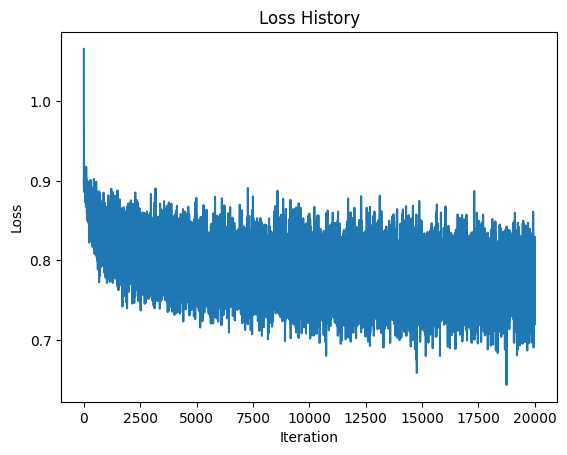

Training accuracy: 41.90%
Test accuracy: 40.94%


In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Data loading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Network parameters
Din = 3 * 32 * 32
H = 100
K = 10
std = 1e-2

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 20
lr = 1e-2
lr_decay = 0.9
reg = 0

loss_history = []


def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))


def forward(x):
    h = sigmoid(x.mm(w1) + b1)
    y = h.mm(w2) + b2
    return h, y


# 3. Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, y_pred = forward(x_train)

        # Loss: MSE + L2 regularization
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        dh = dy_pred.mm(w2.t())
        dh_pre = dh * h * (1 - h)
        dw1 = x_train.t().mm(dh_pre) + reg * w1
        db1 = dh_pre.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plot loss history
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5/6. Accuracy
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, y_pred = forward(x)
            predicted = torch.argmax(y_pred, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


print(f"Training accuracy: {accuracy(trainloader):.2f}%")
print(f"Test accuracy: {accuracy(testloader):.2f}%")

The loss fell from 0.851 to 0.772 over 20 epochs, with most of the drop in the first five epochs and a flattening curve after that. The model reached 41.90% training and 40.94% test accuracy. The gap of about 1 point means there is almost no overfitting, so performance is limited by underfitting. The loss was still decreasing slowly at epoch 20, so the model hadn’t fully converged. The sigmoid derivative is at most 0.25, which shrinks the gradients reaching the first layer and slows training

Epoch 1/20, Loss: 2.205114263296127
Epoch 2/20, Loss: 2.0180324490070345
Epoch 3/20, Loss: 1.941411382317543
Epoch 4/20, Loss: 1.9013623362779617
Epoch 5/20, Loss: 1.8729747498035432
Epoch 6/20, Loss: 1.8504737032651901
Epoch 7/20, Loss: 1.8317948491573335
Epoch 8/20, Loss: 1.8168041186332702
Epoch 9/20, Loss: 1.8043063374757766
Epoch 10/20, Loss: 1.7941047447919845
Epoch 11/20, Loss: 1.7855833222866058
Epoch 12/20, Loss: 1.7783459289073944
Epoch 13/20, Loss: 1.7722822369337081
Epoch 14/20, Loss: 1.7668348828554152
Epoch 15/20, Loss: 1.7622496025562286
Epoch 16/20, Loss: 1.7582097499370575
Epoch 17/20, Loss: 1.754576050400734
Epoch 18/20, Loss: 1.7515157808065414
Epoch 19/20, Loss: 1.7487571992874145
Epoch 20/20, Loss: 1.7463488639593125


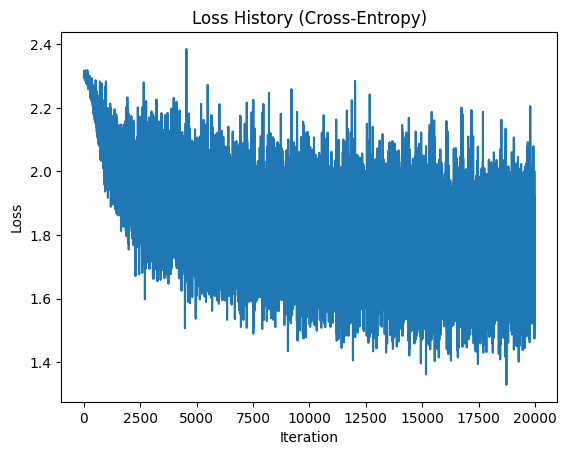

Training accuracy: 38.86%
Test accuracy: 38.62%


In [10]:
def softmax(z):
    z = z - z.max(dim=1, keepdim=True).values
    e = torch.exp(z)
    return e / e.sum(dim=1, keepdim=True)

# 3. Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, y_pred = forward(x_train)
        probs = softmax(y_pred)

        # Cross-entropy loss (+ L2 regularization)
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(probs + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (probs - y_train_onehot) / Ntr
        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        dh = dy_pred.mm(w2.t())
        dh_pre = dh * h * (1 - h)
        dw1 = x_train.t().mm(dh_pre) + reg * w1
        db1 = dh_pre.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plot loss history
plt.plot(loss_history)
plt.title("Loss History (Cross-Entropy)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5/6. Accuracy
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, y_pred = forward(x)
            predicted = torch.argmax(y_pred, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


print(f"Training accuracy: {accuracy(trainloader):.2f}%")
print(f"Test accuracy: {accuracy(testloader):.2f}%")

Cross-entropy started higher (2.205, close to the random-guess value ln 10 ~= 2.30) and fell to 1.746, so its values can’t be compared directly with the MSE losses in part (a). Accuracy was 38.86% on the training set and 38.62% on the test set, about 2.3 points below part (a). The tiny train/test gap (0.24) again points to underfitting. The slower start suggests the learning rate (1e-2) is conservative for cross-entropy, and a larger value would probably help. Since your repeated runs vary by a couple of points, treat the (a) vs (b) difference as roughly a tie rather than evidence that one loss is better.

Epoch 1/10, Loss: 2.2109706490039827
Epoch 2/10, Loss: 2.0217971885204316
Epoch 3/10, Loss: 1.9416033021211625
Epoch 4/10, Loss: 1.900292074084282
Epoch 5/10, Loss: 1.8711513379812241
Epoch 6/10, Loss: 1.8484531207084656
Epoch 7/10, Loss: 1.8300557316541672
Epoch 8/10, Loss: 1.8153080642223358
Epoch 9/10, Loss: 1.8032857484817504
Epoch 10/10, Loss: 1.7931743959188462


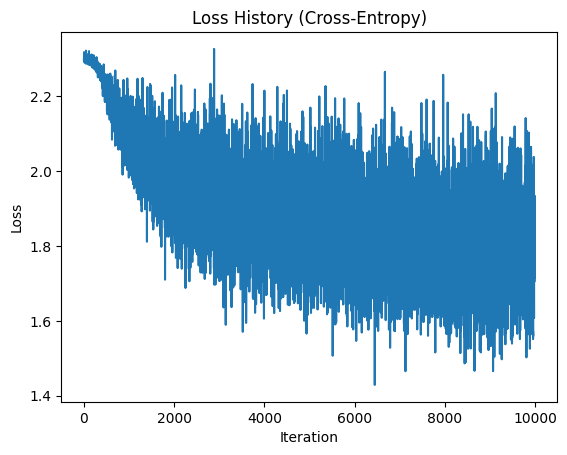

Training accuracy after 10 epochs: 37.22%
Test accuracy after 10 epochs: 37.19%


In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Data loading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Network parameters
Din = 3 * 32 * 32   
H = 100             
K = 10             
std = 1e-2          

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10     
lr = 1e-2           
lr_decay = 0.9
reg = 0

loss_history = []


def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))


def softmax(z):
    z = z - z.max(dim=1, keepdim=True).values   
    e = torch.exp(z)
    return e / e.sum(dim=1, keepdim=True)


def forward(x):
    h = sigmoid(x.mm(w1) + b1)   
    y = h.mm(w2) + b2            
    return h, y


# 3. Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, y_pred = forward(x_train)
        probs = softmax(y_pred)

        # Cross-entropy loss (+ L2 regularization)
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(probs + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (probs - y_train_onehot) / Ntr             
        dw2 = h.t().mm(dy_pred) + reg * w2                  
        db2 = dy_pred.sum(dim=0)                             
        dh = dy_pred.mm(w2.t())                              
        dh_pre = dh * h * (1 - h)                            
        dw1 = x_train.t().mm(dh_pre) + reg * w1              
        db1 = dh_pre.sum(dim=0)                             

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plot loss history
plt.plot(loss_history)
plt.title("Loss History (Cross-Entropy)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5/6. Accuracy
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, y_pred = forward(x)
            predicted = torch.argmax(y_pred, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


print(f"Training accuracy after {iterations} epochs: {accuracy(trainloader):.2f}%")
print(f"Test accuracy after {iterations} epochs: {accuracy(testloader):.2f}%")

After 10 epochs the loss reached 1.793, with 37.22% training and 37.19% test accuracy. This is about 1.6 points lower than the 20-epoch run in part (b) (38.86% train, 38.62% test), which is what you’d expect from half as many updates. The loss at epoch 10 here (1.793) almost matches part (b)’s loss at epoch 10 (1.794), so the 10-epoch run is essentially the first half of the 20-epoch run. The loss is still falling steadily at epoch 10 and the train/test gap is only 0.03 points, so the model is clearly underfitting rather than overfitting, and more epochs or a larger learning rate would raise accuracy. The learning-rate decay of 0.9 per epoch also shrinks the later updates, which is why the curve flattens.

## Question 02

Using device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 54.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 2.46MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 13.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.66MB/s]


LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=400, out_features=120, bias=True)
    (2): Tanh()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): Tanh()
    (5): Linear(in_features=84, out_features=10, bias=True)
  )
)
Epoch 1/10, Loss: 0.2489
Epoch 2/10, Loss: 0.0727
Epoch 3/10, Loss: 0.0511
Epoch 4/10, Loss: 0.0406
Epoch 5/10, Loss: 0.0321
Epoch 6/10, Loss: 0.0256
Epoch 7/10, Loss: 0.0239
Epoch 8/10, Loss: 0.0195
Epoch 9/10, Loss: 0.0180
Epoch 10/10, Loss: 0.0143


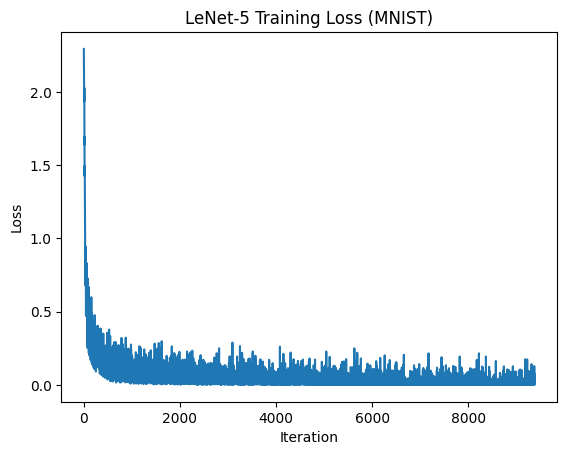

Training accuracy after 10 epochs: 99.61%
Test accuracy after 10 epochs: 98.77%


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 1. Data loading (MNIST, 28x28 grayscale)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])

batch_size = 64
trainset = torchvision.datasets.MNIST(root='./data', train=True,
                                      download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=0)
testset = torchvision.datasets.MNIST(root='./data', train=False,
                                     download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=0)


# 2. LeNet-5 definition
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # C1: 1x28x28 -> 6x28x28 (padding=2 gives the classic 32x32 input size)
            nn.Conv2d(1, 6, kernel_size=5, padding=2),
            nn.Tanh(),
            # S2: 6x28x28 -> 6x14x14
            nn.AvgPool2d(kernel_size=2, stride=2),
            # C3: 6x14x14 -> 16x10x10
            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),
            # S4: 16x10x10 -> 16x5x5
            nn.AvgPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120),   
            nn.Tanh(),
            nn.Linear(120, 84),           
            nn.Tanh(),
            nn.Linear(84, 10),           
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = LeNet5().to(device)
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
epochs = 10


def accuracy(loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            predicted = model(inputs).argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


# 3. Training loop
loss_history = []
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        loss = criterion(model(inputs), labels)
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())
        running_loss += loss.item()

    print(f"Epoch {epoch + 1}/{epochs}, Loss: {running_loss / len(trainloader):.4f}")

# 4. Loss plot
plt.plot(loss_history)
plt.title("LeNet-5 Training Loss (MNIST)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Final accuracies after 10 epochs
print(f"Training accuracy after {epochs} epochs: {accuracy(trainloader):.2f}%")
print(f"Test accuracy after {epochs} epochs: {accuracy(testloader):.2f}%")

LeNet-5 reached 99.61% training and 98.77% test accuracy after 10 epochs, with the loss falling from 0.249 to 0.014. This is far above the fully connected CIFAR-10 networks in Question 1 (about 37 to 42%). Convolutions share weights and detect local patterns, and pooling adds tolerance to small shifts, so the network learns image structure that dense layers on flattened pixels miss (MNIST is also an easier dataset). The small train/test gap (about 0.8 points) shows good generalisation with only mild overfitting.

Using device: cpu
SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=1152, out_

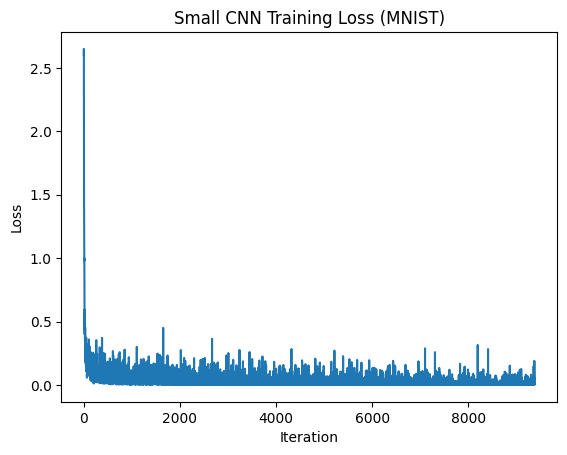

Training accuracy after 10 epochs: 99.72%
Test accuracy after 10 epochs: 99.23%


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 1. Data loading (identical to the LeNet-5 setup)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])

batch_size = 64
trainset = torchvision.datasets.MNIST(root='./data', train=True,
                                      download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=0)
testset = torchvision.datasets.MNIST(root='./data', train=False,
                                     download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=0)


# 2. Small modern CNN: 3 conv layers + BatchNorm + ReLU + MaxPool, with dropout
class SmallCNN(nn.Module):
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 1x28x28 -> 32x14x14
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Block 2: 32x14x14 -> 64x7x7
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Block 3: 64x7x7 -> 128x3x3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p_drop),
            nn.Linear(128 * 3 * 3, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = SmallCNN().to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# Same training conditions as LeNet-5: cross-entropy, Adam lr=1e-3, 10 epochs
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
epochs = 10


def accuracy(loader):
    model.eval()   
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            predicted = model(inputs).argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


# 3. Training loop
loss_history = []
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        loss = criterion(model(inputs), labels)
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())
        running_loss += loss.item()

    print(f"Epoch {epoch + 1}/{epochs}, Loss: {running_loss / len(trainloader):.4f}")

# 4. Loss plot
plt.plot(loss_history)
plt.title("Small CNN Training Loss (MNIST)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Final accuracies after 10 epochs
print(f"Training accuracy after {epochs} epochs: {accuracy(trainloader):.2f}%")
print(f"Test accuracy after {epochs} epochs: {accuracy(testloader):.2f}%")

The small CNN reached 99.72% training and 99.23% test accuracy, compared with 99.61% and 98.77% for LeNet-5, which is about 40% fewer test errors. It also converged faster (epoch-1 loss 0.113 vs 0.249) and had a smaller train/test gap (0.49 vs 0.84 points). Batch normalisation stabilises training, ReLU avoids Tanh saturation, and dropout reduces overfitting. Part of the gain may come from its larger size (104,650 vs about 61,700 parameters), and single runs vary slightly, so the improvement is modest but consistent with the modern design.

Using device: cpu
[LeNet-5] Epoch 1/10 | train loss 0.0851, acc 97.47% | test loss 0.0853, acc 97.44%
[LeNet-5] Epoch 2/10 | train loss 0.0588, acc 98.21% | test loss 0.0641, acc 97.97%
[LeNet-5] Epoch 3/10 | train loss 0.0360, acc 98.89% | test loss 0.0476, acc 98.37%
[LeNet-5] Epoch 4/10 | train loss 0.0325, acc 99.00% | test loss 0.0485, acc 98.39%
[LeNet-5] Epoch 5/10 | train loss 0.0325, acc 98.97% | test loss 0.0557, acc 98.53%
[LeNet-5] Epoch 6/10 | train loss 0.0241, acc 99.23% | test loss 0.0448, acc 98.63%
[LeNet-5] Epoch 7/10 | train loss 0.0220, acc 99.30% | test loss 0.0524, acc 98.42%
[LeNet-5] Epoch 8/10 | train loss 0.0193, acc 99.39% | test loss 0.0500, acc 98.52%
[LeNet-5] Epoch 9/10 | train loss 0.0135, acc 99.59% | test loss 0.0432, acc 98.74%
[LeNet-5] Epoch 10/10 | train loss 0.0116, acc 99.62% | test loss 0.0443, acc 98.67%
[Small CNN] Epoch 1/10 | train loss 0.0472, acc 98.52% | test loss 0.0485, acc 98.51%
[Small CNN] Epoch 2/10 | train loss 0.0307, acc 98.97% 

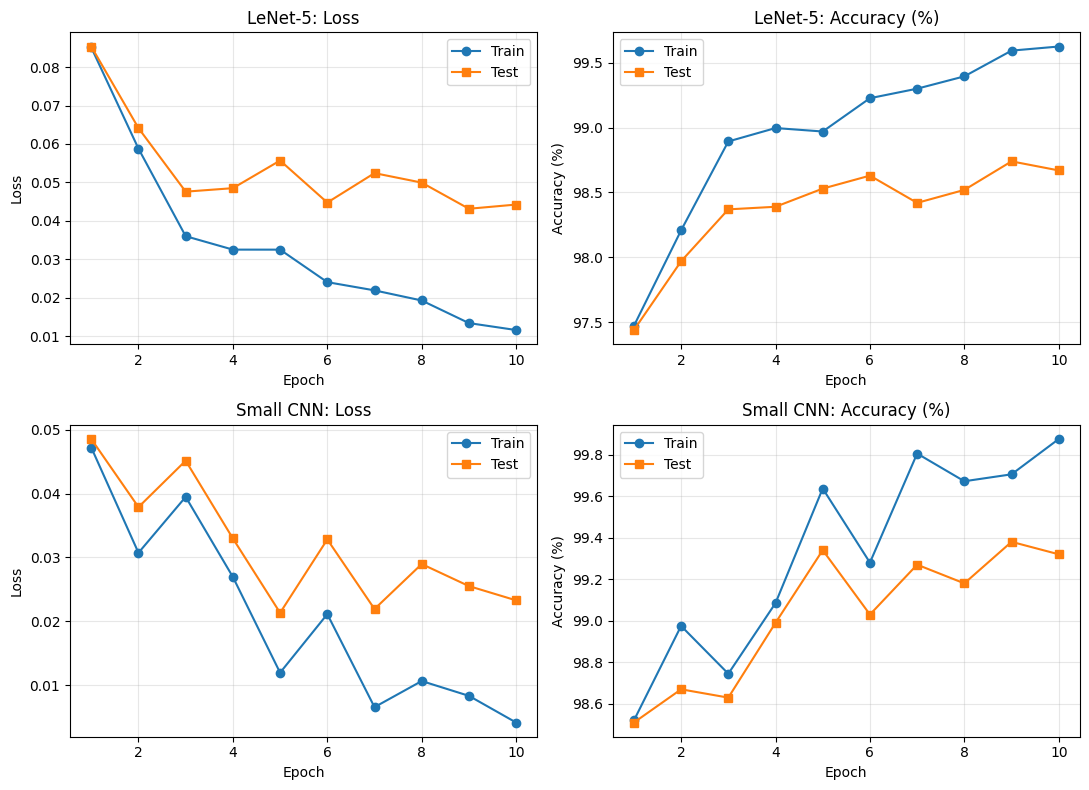

LeNet-5: 133 misclassified test images out of 10000
Small CNN: 68 misclassified test images out of 10000


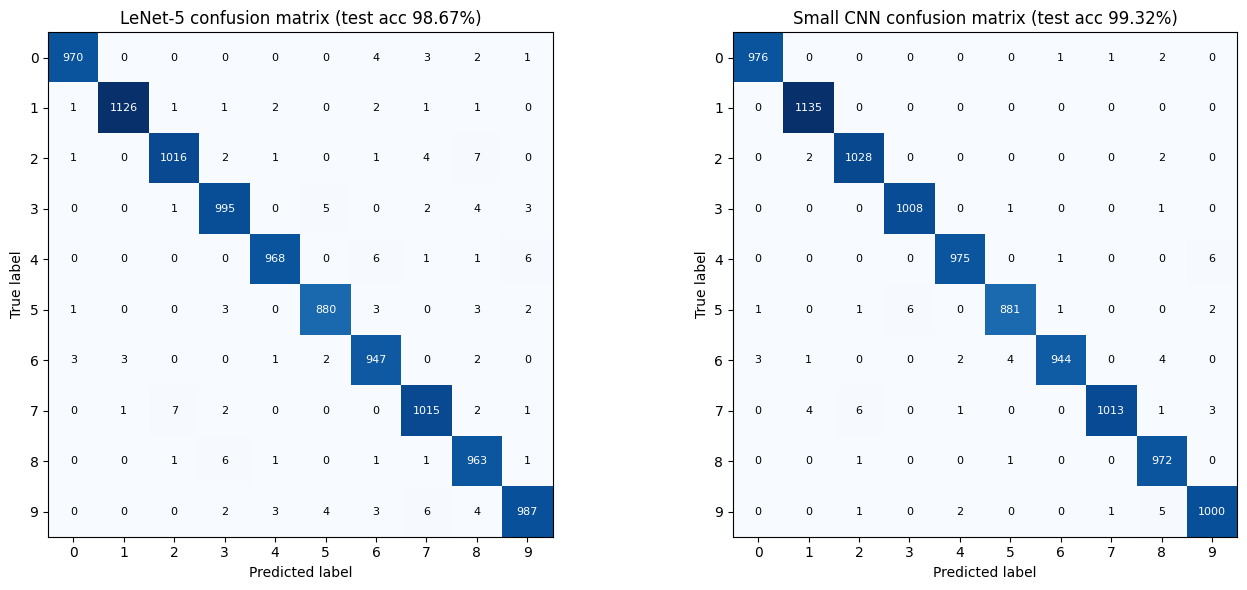

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 1. Data loading (same for both models)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])

batch_size = 64
trainset = torchvision.datasets.MNIST(root='./data', train=True,
                                      download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=0)
testset = torchvision.datasets.MNIST(root='./data', train=False,
                                     download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=0)


# 2. Model definitions
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.Tanh(),
            nn.AvgPool2d(2, 2),
            nn.Conv2d(6, 16, kernel_size=5), nn.Tanh(),
            nn.AvgPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class SmallCNN(nn.Module):
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p_drop),
            nn.Linear(128 * 3 * 3, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


criterion = nn.CrossEntropyLoss()
epochs = 10


# 3. Evaluation helper: returns loss, accuracy (%), and (optionally) all predictions/labels
def evaluate(model, loader, return_preds=False):
    model.eval()   
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            if return_preds:
                all_preds.append(preds.cpu())
                all_labels.append(labels.cpu())
    loss, acc = total_loss / total, 100 * correct / total
    if return_preds:
        return loss, acc, torch.cat(all_preds), torch.cat(all_labels)
    return loss, acc


# 4. Training with per-epoch logging
def train_model(model, name):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for epoch in range(epochs):
        model.train()
        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()

        # End-of-epoch evaluation in eval mode on both sets
        tr_loss, tr_acc = evaluate(model, trainloader)
        te_loss, te_acc = evaluate(model, testloader)
        history["train_loss"].append(tr_loss)
        history["test_loss"].append(te_loss)
        history["train_acc"].append(tr_acc)
        history["test_acc"].append(te_acc)
        print(f"[{name}] Epoch {epoch + 1}/{epochs} | "
              f"train loss {tr_loss:.4f}, acc {tr_acc:.2f}% | "
              f"test loss {te_loss:.4f}, acc {te_acc:.2f}%")
    return model, history


models, histories = {}, {}
for name, net in [("LeNet-5", LeNet5()), ("Small CNN", SmallCNN())]:
    models[name], histories[name] = train_model(net, name)

# 5. Plot per-epoch loss and accuracy for both models
ep = range(1, epochs + 1)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, name in enumerate(histories):
    h = histories[name]
    axes[row, 0].plot(ep, h["train_loss"], marker='o', label="Train")
    axes[row, 0].plot(ep, h["test_loss"], marker='s', label="Test")
    axes[row, 0].set_title(f"{name}: Loss")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 0].set_ylabel("Loss")
    axes[row, 0].legend()
    axes[row, 0].grid(alpha=0.3)

    axes[row, 1].plot(ep, h["train_acc"], marker='o', label="Train")
    axes[row, 1].plot(ep, h["test_acc"], marker='s', label="Test")
    axes[row, 1].set_title(f"{name}: Accuracy (%)")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 1].set_ylabel("Accuracy (%)")
    axes[row, 1].legend()
    axes[row, 1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Confusion matrices on the test set
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, models):
    _, acc, preds, labels = evaluate(models[name], testloader, return_preds=True)
    cm = torch.bincount(labels * 10 + preds, minlength=100).reshape(10, 10) 
    ax.imshow(cm.numpy(), cmap="Blues")
    ax.set_title(f"{name} confusion matrix (test acc {acc:.2f}%)")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    thresh = cm.max().item() / 2
    for i in range(10):
        for j in range(10):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > thresh else "black")

    errors = cm.sum().item() - cm.diag().sum().item()
    print(f"{name}: {errors} misclassified test images out of {cm.sum().item()}")
plt.tight_layout()
plt.show()

The small CNN outperformed LeNet-5 from the first epoch (98.51% vs 97.44% test accuracy) and finished at 99.32% vs 98.67%, with 68 misclassified test images against 133. LeNet-5 shows mild overfitting: its training loss keeps falling (0.085 -> 0.012) while its test loss stalls around 0.044 to 0.056. The small CNN has a smaller train/test gap (about 0.56 vs 0.95 points), thanks to dropout and batch normalisation, but its curves are noisier from epoch to epoch. In both confusion matrices nearly all counts lie on the diagonal, and the small CNN has fewer errors in most classes.